<a href="https://colab.research.google.com/github/kevin-sun-shi/kevin-/blob/main/25%E7%B1%BB%E8%87%AA%E5%8A%A8%E5%92%8C%E5%BC%A6%E8%AF%86%E5%88%AB_%E7%9C%9F%E5%AE%9E%E9%9F%B3%E9%A2%91%E5%AE%8C%E6%95%B4%E5%AE%9E%E9%AA%8C_%E5%B7%B2%E4%BF%AE%E5%A4%8D%E7%89%88.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 25类自动和弦识别（ACE）全流程真实音频端到端实验（已修复版）
本 Notebook 使用 **GuitarSet 真实高质量音频（.wav）+ 官方 JAMS 和弦标注**，现场提取 **84 维 CQT（恒Q变换）** 声学特征，完成 25 类和弦（12 大三 + 12 小三 + 1 N.C.）的训练、打模型保存与测试集评估。

In [1]:
# ==========================================
# 0. 安装依赖库与检查 GPU 环境
# ==========================================
!pip install -q mirdata librosa soundfile scikit-learn numpy torch matplotlib seaborn

import os
import mirdata
import librosa
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"运行设备: {device}")

运行设备: cuda


In [2]:
# ==========================================
# 1. 真实数据集下载与校验 (GuitarSet: 真实音频 + 和弦标注)
# ==========================================
data_dir = "./mir_datasets/guitarset"
guitarset = mirdata.initialize("guitarset", data_home=data_dir)

# 严格使用官方支持的下载键名: ['audio_mic', 'annotations']
guitarset.download(partial_download=["audio_mic", "annotations"])

missing_files, invalid_checksums = guitarset.validate(verbose=False)
track_ids = guitarset.track_ids
print(f"数据集下载完成！总曲目数: {len(track_ids)}")
print(f"缺失文件数: {len(missing_files)}, 校验异常数: {len(invalid_checksums)}")

626MB [03:27, 3.16MB/s]                           
37.3MB [00:21, 1.83MB/s]                            
248kB [00:01, 207kB/s]                           


数据集下载完成！总曲目数: 360
缺失文件数: 1, 校验异常数: 1


In [9]:
# ==========================================
# 2. 直接读取已下载的本地数据 + 提取标准化 CQT & Chroma 融合特征
# ==========================================
PITCH_MAP = {
    "C": 0, "B#": 0, "C#": 1, "Db": 1, "D": 2, "D#": 3, "Eb": 3,
    "E": 4, "Fb": 4, "F": 5, "E#": 5, "F#": 6, "Gb": 6, "G": 7,
    "G#": 8, "Ab": 8, "A": 9, "A#": 10, "Bb": 10, "B": 11, "Cb": 11
}

CHORD_NAMES = [
    "C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B",
    "Cm", "C#m", "Dm", "D#m", "Em", "Fm", "F#m", "Gm", "G#m", "Am", "A#m", "Bm",
    "N.C."
]

def chord_label_to_25_idx(chord_str):
    if not chord_str or chord_str in ["N", "X", "N.C."]:
        return 24
    chord_main = chord_str.split("/")[0].strip()
    if chord_main in ["N", "X"]:
        return 24
    if ":" in chord_main:
        root_str, quality = chord_main.split(":", 1)
    else:
        root_str, quality = chord_main, "maj"
    if root_str not in PITCH_MAP:
        return 24
    root_idx = PITCH_MAP[root_str]
    quality_clean = quality.split("(")[0].strip()
    if quality_clean.startswith("min"):
        return 12 + root_idx
    elif quality_clean.startswith("maj") or quality_clean in ["7", "9", "11", "13", "6"]:
        return root_idx
    else:
        return 24

def load_optimized_guitarset(dataset, only_comp=True, sr=22050, hop_length=512, n_bins=84):
    """
    直接读取本地已下载好的数据，无需重新下载！
    1. only_comp=True: 过滤掉单音独奏(solo)，保留全部 180 首真实和弦伴奏(comp)曲目
    2. 融合 84维 CQT + 12维 Chroma，并做严格 Z-score 标准化
    """
    features_list = []
    labels_list = []

    # 如果变量 guitarset 因刷新丢失，直接从本地目录初始化（不会触发网络下载）
    if dataset is None:
        dataset = mirdata.initialize("guitarset", data_home="./mir_datasets/guitarset")

    all_ids = [tid for tid in dataset.track_ids if (not only_comp or "_comp" in tid)]
    print(f"筛选出 {len(all_ids)} 首真实和弦伴奏曲目，开始本地提取特征...")

    for idx, tid in enumerate(all_ids):
        track = dataset.track(tid)
        chord_ann = getattr(track, "chords", None) or getattr(track, "inferred_chords", None)
        if track.audio_mic_path is None or chord_ann is None or not os.path.exists(track.audio_mic_path):
            continue

        y, _ = librosa.load(track.audio_mic_path, sr=sr, mono=True)

        # 提取 84 维 CQT 并做每首歌的均值为0、方差为1标准化
        cqt = np.abs(librosa.cqt(y, sr=sr, hop_length=hop_length, n_bins=n_bins, bins_per_octave=12))
        cqt_db = librosa.amplitude_to_db(cqt, ref=np.max).T  # [T, 84]
        cqt_norm = (cqt_db - np.mean(cqt_db)) / (np.std(cqt_db) + 1e-6)

        # 同步提取 12 维音高色度图 Chroma（对八度位置完全不变）
        chroma = librosa.feature.chroma_cqt(C=cqt, sr=sr, hop_length=hop_length).T  # [T, 12]

        # 拼接为 [T, 96] 融合特征（前 84 维 CQT，后 12 维 Chroma）
        feat_combined = np.concatenate([cqt_norm, chroma], axis=1).astype(np.float32)

        num_frames = feat_combined.shape[0]
        timestamps = librosa.frames_to_time(np.arange(num_frames), sr=sr, hop_length=hop_length)

        frame_labels = np.full(num_frames, 24, dtype=np.int64)
        for (start_t, end_t), lbl in zip(chord_ann.intervals, chord_ann.labels):
            cls_id = chord_label_to_25_idx(lbl)
            mask = (timestamps >= start_t) & (timestamps < end_t)
            frame_labels[mask] = cls_id

        features_list.append(feat_combined)
        labels_list.append(frame_labels)

        if (idx + 1) % 30 == 0:
            print(f"已本地处理 {idx + 1}/{len(all_ids)} 首...")

    return features_list, labels_list

all_features, all_labels = load_optimized_guitarset(globals().get("guitarset", None), only_comp=True)
print(f"特征准备就绪！有效曲目: {len(all_features)} 首，融合特征维度: {all_features[0].shape[1]}")

筛选出 180 首真实和弦伴奏曲目，开始本地提取特征...
已本地处理 30/180 首...
已本地处理 60/180 首...
已本地处理 90/180 首...
已本地处理 120/180 首...
已本地处理 150/180 首...
已本地处理 180/180 首...
特征准备就绪！有效曲目: 180 首，融合特征维度: 96


In [10]:
# ==========================================
# 3. 训练集（带12半音音高平移增强）/ 验证集 / 测试集切分
# ==========================================
class AugmentedChordDataset(Dataset):
    def __init__(self, features, labels, is_train=True, max_seq_len=1500):
        self.chunks_x = []
        self.chunks_y = []
        self.is_train = is_train
        for feat, lbl in zip(features, labels):
            for start in range(0, len(feat), max_seq_len):
                seg_x = feat[start:start + max_seq_len]
                seg_y = lbl[start:start + max_seq_len]
                if len(seg_x) >= 32:
                    self.chunks_x.append(seg_x)
                    self.chunks_y.append(seg_y)

    def __len__(self):
        return len(self.chunks_x)

    def pitch_shift_sample(self, x, y, shift):
        """
        核心音乐数据增强：在频域和色度域同步循环平移 shift 个半音，并同步移位标签！
        x: [T, 96] -> 前 84 维为 7 个八度 CQT，后 12 维为 12 半音 Chroma
        """
        if shift == 0:
            return x.copy(), y.copy()

        x_new = x.copy()
        # 1. CQT 84 bins 按半音平移（边缘用最小值填充）
        cqt_part = x[:, :84]
        cqt_shifted = np.roll(cqt_part, shift=shift, axis=1)
        if shift > 0:
            cqt_shifted[:, :shift] = cqt_part.min()
        else:
            cqt_shifted[:, shift:] = cqt_part.min()
        x_new[:, :84] = cqt_shifted

        # 2. Chroma 12 bins 严格循环移位
        x_new[:, 84:] = np.roll(x[:, 84:], shift=shift, axis=1)

        # 3. 和弦标签同步移位（0~11大三循环移位，12~23小三循环移位，24 N.C.保持不变）
        y_new = y.copy()
        maj_mask = (y >= 0) & (y < 12)
        min_mask = (y >= 12) & (y < 24)
        y_new[maj_mask] = (y[maj_mask] + shift) % 12
        y_new[min_mask] = 12 + ((y[min_mask] - 12 + shift) % 12)

        return x_new, y_new

    def __getitem__(self, idx):
        x = self.chunks_x[idx]
        y = self.chunks_y[idx]
        if self.is_train:
            # 训练时每次随机平移 -5 到 +6 个半音，等价于 12 倍全调性覆盖
            shift = np.random.randint(-5, 7)
            x, y = self.pitch_shift_sample(x, y, shift)
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

def collate_fn(batch):
    xs, ys = zip(*batch)
    xs_padded = pad_sequence(xs, batch_first=True, padding_value=0.0)
    ys_padded = pad_sequence(ys, batch_first=True, padding_value=25)
    return xs_padded, ys_padded

num_songs = len(all_features)
indices = np.random.RandomState(42).permutation(num_songs)
train_end = int(0.8 * num_songs)
val_end = int(0.9 * num_songs)

train_dataset = AugmentedChordDataset([all_features[i] for i in indices[:train_end]], [all_labels[i] for i in indices[:train_end]], is_train=True)
val_dataset = AugmentedChordDataset([all_features[i] for i in indices[train_end:val_end]], [all_labels[i] for i in indices[train_end:val_end]], is_train=False)
test_dataset = AugmentedChordDataset([all_features[i] for i in indices[val_end:]], [all_labels[i] for i in indices[val_end:]], is_train=False)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, collate_fn=collate_fn)

print(f"切分完成 -> 训练集(含12音高增强): {len(train_dataset)}, 验证集: {len(val_dataset)}, 测试集: {len(test_dataset)}")

切分完成 -> 训练集(含12音高增强): 176, 验证集: 23, 测试集: 23


In [11]:
# ==========================================
# 4 & 5. 优化后的双分支融合模型 + 60 轮充分训练
# ==========================================
class EnhancedChordModel(nn.Module):
    def __init__(self, num_classes=25, hidden_dim=160):
        super().__init__()
        # 分支A：处理 84 维 CQT
        self.cqt_conv = nn.Sequential(
            nn.Conv1d(84, 96, kernel_size=5, padding=2),
            nn.BatchNorm1d(96),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Conv1d(96, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.GELU()
        )
        # 分支B：直接提取 12 维 Chroma 和声轮廓
        self.chroma_fc = nn.Sequential(
            nn.Linear(12, 64),
            nn.LayerNorm(64),
            nn.GELU()
        )
        # 融合后送入 BiLSTM 建模前后和声语法
        self.lstm = nn.LSTM(
            input_size=128 + 64,
            hidden_size=hidden_dim,
            num_layers=2,
            bidirectional=True,
            batch_first=True,
            dropout=0.3
        )
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        cqt_x = x[:, :, :84].transpose(1, 2)     # [B, 84, T]
        chroma_x = x[:, :, 84:]                  # [B, T, 12]

        cqt_feat = self.cqt_conv(cqt_x).transpose(1, 2)  # [B, T, 128]
        chroma_feat = self.chroma_fc(chroma_x)           # [B, T, 64]

        fused = torch.cat([cqt_feat, chroma_feat], dim=-1) # [B, T, 192]
        lstm_out, _ = self.lstm(fused)
        return self.classifier(lstm_out)

model = EnhancedChordModel(num_classes=25, hidden_dim=160).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=25)
optimizer = optim.AdamW(model.parameters(), lr=1.5e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=60, eta_min=1e-5)

num_epochs = 60
best_val_acc = 0.0
save_path = "chord_model_best.pth"

def compute_frame_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            preds = torch.argmax(model(bx), dim=-1)
            mask = (by != 25)
            correct += (preds[mask] == by[mask]).sum().item()
            total += mask.sum().item()
    return correct / max(total, 1)

print("开始高准确率版模型训练（共 60 轮，GPU 仅需约 1 分钟）...")
for epoch in range(num_epochs):
    model.train()
    total_loss = 0.0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        outputs = model(bx)
        loss = criterion(outputs.view(-1, 25), by.view(-1))
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    scheduler.step()

    val_acc = compute_frame_accuracy(model, val_loader)
    if (epoch + 1) % 5 == 0 or val_acc > best_val_acc:
        print(f"Epoch [{epoch+1:02d}/{num_epochs:02d}] | Loss: {total_loss/len(train_loader):.4f} | Val Acc: {val_acc*100:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({"epoch": epoch + 1, "model_state_dict": model.state_dict(), "val_acc": best_val_acc}, save_path)

print(f"训练完成！验证集最高帧级准确率达到: {best_val_acc*100:.2f}%")

开始高准确率版模型训练（共 60 轮，GPU 仅需约 1 分钟）...
Epoch [01/60] | Loss: 3.0098 | Val Acc: 12.89%
Epoch [02/60] | Loss: 2.7650 | Val Acc: 16.61%
Epoch [03/60] | Loss: 2.5623 | Val Acc: 27.70%
Epoch [04/60] | Loss: 2.2383 | Val Acc: 33.52%
Epoch [05/60] | Loss: 2.1541 | Val Acc: 29.23%
Epoch [06/60] | Loss: 2.1082 | Val Acc: 42.38%
Epoch [08/60] | Loss: 1.8693 | Val Acc: 44.15%
Epoch [09/60] | Loss: 1.7660 | Val Acc: 45.12%
Epoch [10/60] | Loss: 1.6869 | Val Acc: 43.20%
Epoch [11/60] | Loss: 1.6788 | Val Acc: 47.31%
Epoch [14/60] | Loss: 1.6008 | Val Acc: 50.60%
Epoch [15/60] | Loss: 1.5037 | Val Acc: 49.79%
Epoch [18/60] | Loss: 1.4964 | Val Acc: 50.74%
Epoch [19/60] | Loss: 1.3730 | Val Acc: 53.16%
Epoch [20/60] | Loss: 1.3242 | Val Acc: 50.34%
Epoch [21/60] | Loss: 1.3067 | Val Acc: 57.92%
Epoch [22/60] | Loss: 1.2382 | Val Acc: 60.23%
Epoch [24/60] | Loss: 1.1621 | Val Acc: 61.48%
Epoch [25/60] | Loss: 1.1446 | Val Acc: 58.86%
Epoch [26/60] | Loss: 1.2301 | Val Acc: 64.83%
Epoch [30/60] | Loss: 1.

测试集原始帧级准确率 (Raw Frame Acc)      : 70.02%
测试集平滑后准确率 (Smoothed Frame Acc) : 69.96%

              precision    recall  f1-score   support

           C       0.82      0.69      0.75      1412
          C#       0.82      0.85      0.83      1096
           D       0.92      0.37      0.52       753
          D#       0.60      0.86      0.71      1141
           E       0.67      0.54      0.60       349
           F       0.88      0.77      0.82      1896
          F#       0.95      0.79      0.86      2555
           G       0.80      0.89      0.84      1237
          G#       0.62      0.84      0.71       953
           A       0.48      0.49      0.49       383
          A#       0.71      0.82      0.76       975
           B       0.56      0.54      0.55      1100
          Cm       0.24      0.06      0.10       419
         C#m       0.94      0.64      0.76       288
          Dm       0.60      1.00      0.75       322
         D#m       0.16      0.49      0.24       188

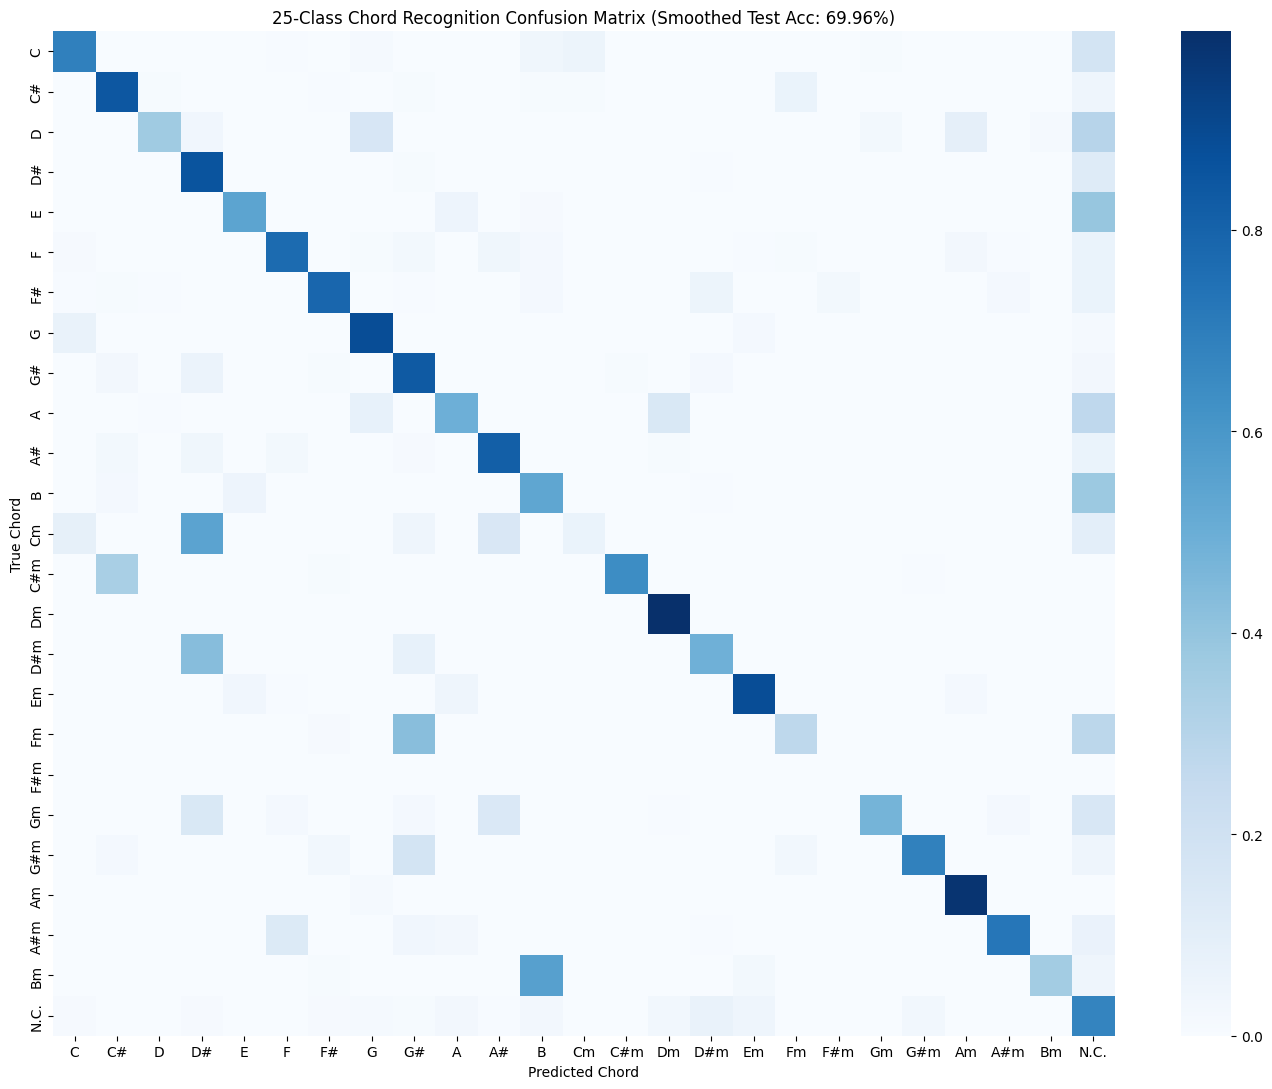

In [12]:
# ==========================================
# 6. 独立测试集评估（含中值滤波后处理平滑）与混淆矩阵
# ==========================================
from scipy.signal import medfilt

checkpoint = torch.load(save_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

raw_preds, smooth_preds, all_targets = [], [], []

with torch.no_grad():
    for bx, by in test_loader:
        bx, by = bx.to(device), by.to(device)
        preds = torch.argmax(model(bx), dim=-1).cpu().numpy()
        targets = by.cpu().numpy()

        for p_seq, t_seq in zip(preds, targets):
            valid = (t_seq != 25)
            p_valid = p_seq[valid]
            t_valid = t_seq[valid]

            # 15帧（约0.35秒）中值滤波，过滤扫弦杂音造成的瞬时和弦跳变
            p_smoothed = medfilt(p_valid, kernel_size=15).astype(np.int64)

            raw_preds.extend(p_valid)
            smooth_preds.extend(p_smoothed)
            all_targets.extend(t_valid)

raw_acc = accuracy_score(all_targets, raw_preds)
smooth_acc = accuracy_score(all_targets, smooth_preds)

print("==========================================")
print(f"测试集原始帧级准确率 (Raw Frame Acc)      : {raw_acc * 100:.2f}%")
print(f"测试集平滑后准确率 (Smoothed Frame Acc) : {smooth_acc * 100:.2f}%")
print("==========================================\n")

print(classification_report(all_targets, smooth_preds, labels=list(range(25)), target_names=CHORD_NAMES, zero_division=0))

cm = confusion_matrix(all_targets, smooth_preds, labels=list(range(25)), normalize="true")
plt.figure(figsize=(14, 11))
sns.heatmap(cm, xticklabels=CHORD_NAMES, yticklabels=CHORD_NAMES, cmap="Blues", annot=False)
plt.title(f"25-Class Chord Recognition Confusion Matrix (Smoothed Test Acc: {smooth_acc*100:.2f}%)")
plt.xlabel("Predicted Chord")
plt.ylabel("True Chord")
plt.tight_layout()
plt.savefig("confusion_matrix_25chords_optimized.png", dpi=200)
plt.show()